In [9]:

# ============================================================
# 1. IMPORTS AND PROJECT PATHS
# ============================================================

import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project root: one directory above notebooks/
PROJECT_ROOT = Path.cwd().parent

DATASET_PATH = (
    PROJECT_ROOT
    / "data/tapvid_davis/tapvid_davis/tapvid_davis.pkl"
)

RESULTS_DIR = PROJECT_ROOT / "results/davis/breakdance"

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATASET_PATH.exists())
print("Results directory exists:", RESULTS_DIR.exists())

assert DATASET_PATH.exists(), "TAP-Vid dataset not found!"
assert RESULTS_DIR.exists(), "Results directory not found!"


# ============================================================
# 2. LOAD TAP-VID DATASET
# ============================================================

print("\nLoading TAP-Vid dataset...")

with open(DATASET_PATH, "rb") as f:
    dataset = pickle.load(f)

sample = dataset["breakdance"]

video = sample["video"]
gt_points_original = sample["points"]
gt_occluded_original = sample["occluded"]

N_FRAMES, H, W, _ = video.shape

print("Dataset loaded!")
print("Video shape:", video.shape)
print("Resolution:", W, "x", H)
print("Number of annotated points:", len(gt_points_original))


# ============================================================
# 3. LOAD QUERY POINTS
# ============================================================

valid = np.load(RESULTS_DIR / "valid_points.npy")

# Keep the 21 points initially visible at frame 0
gt_points = gt_points_original[valid].copy()
gt_occluded = gt_occluded_original[valid].copy()

# TAP-Vid coordinates are normalized [0, 1].
# Convert them to original image pixel coordinates.
gt_points[..., 0] *= W - 1
gt_points[..., 1] *= H - 1

print("\nGround truth:")
print("Points:", gt_points.shape)
print("Occlusion:", gt_occluded.shape)


# ============================================================
# 4. LOAD COTRACKER3 PREDICTIONS
# ============================================================

cotracker_tracks = np.load(
    RESULTS_DIR / "tracks.npy"
)

cotracker_visibility = np.load(
    RESULTS_DIR / "visibility.npy"
)

print("\nCoTracker3:")
print("Tracks:", cotracker_tracks.shape)
print("Visibility:", cotracker_visibility.shape)


# ============================================================
# 5. LOAD VGGT PREDICTIONS
# ============================================================

vggt_tracks = np.load(
    RESULTS_DIR / "vggt_tracks.npy"
)

vggt_visibility = np.load(
    RESULTS_DIR / "vggt_visibility.npy"
)

vggt_confidence = np.load(
    RESULTS_DIR / "vggt_confidence.npy"
)

print("\nVGGT:")
print("Tracks:", vggt_tracks.shape)
print("Visibility:", vggt_visibility.shape)
print("Confidence:", vggt_confidence.shape)


# ============================================================
# 6. CONVERT VGGT COORDINATES TO ORIGINAL RESOLUTION
# ============================================================

# VGGT processed images at 924 x 518.
# TAP-Vid and CoTracker3 use 854 x 480.

VGGT_W = 924
VGGT_H = 518

vggt_tracks = vggt_tracks.copy()

vggt_tracks[..., 0] *= W / VGGT_W
vggt_tracks[..., 1] *= H / VGGT_H

print("\nVGGT coordinates converted to original resolution.")


# ============================================================
# 7. BASIC CONSISTENCY CHECKS
# ============================================================

N_QUERY_POINTS = gt_points.shape[0]

assert cotracker_tracks.shape[1] == N_QUERY_POINTS
assert vggt_tracks.shape[1] == N_QUERY_POINTS

assert cotracker_tracks.shape[0] == N_FRAMES
assert gt_points.shape[1] == N_FRAMES

assert vggt_tracks.shape[0] <= N_FRAMES

print("\nAll data loaded successfully!")
print("Number of original annotated points:", len(valid))
print("Number of valid query points:", N_QUERY_POINTS)
print("Original video resolution:", W, "x", H)
print("Frames available for VGGT:", vggt_tracks.shape[0])

Project root: <project root>
Dataset exists: True
Results directory exists: True

Loading TAP-Vid dataset...
Dataset loaded!
Video shape: (84, 480, 854, 3)
Resolution: 854 x 480
Number of annotated points: 25

Ground truth:
Points: (21, 84, 2)
Occlusion: (21, 84)

CoTracker3:
Tracks: (84, 21, 2)
Visibility: (84, 21)

VGGT:
Tracks: (18, 21, 2)
Visibility: (18, 21)
Confidence: (18, 21)

VGGT coordinates converted to original resolution.

All data loaded successfully!
Number of original annotated points: 25
Number of valid query points: 21
Original video resolution: 854 x 480
Frames available for VGGT: 18


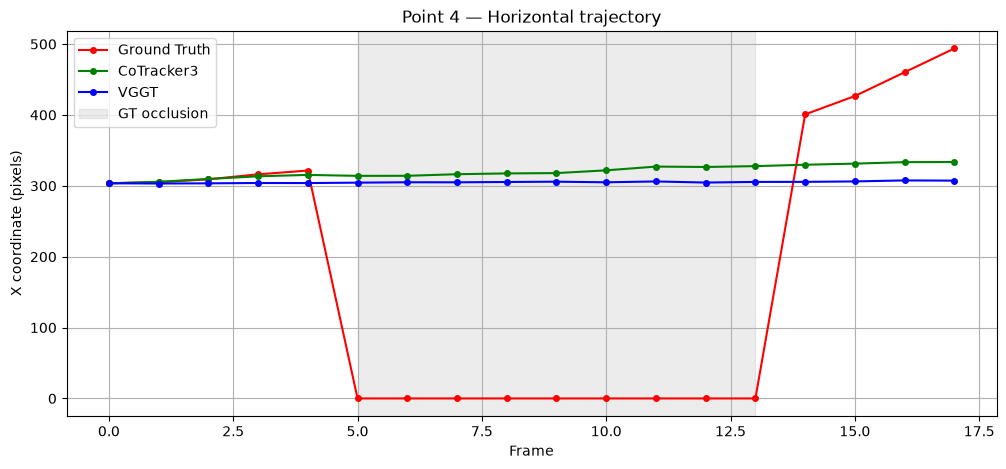

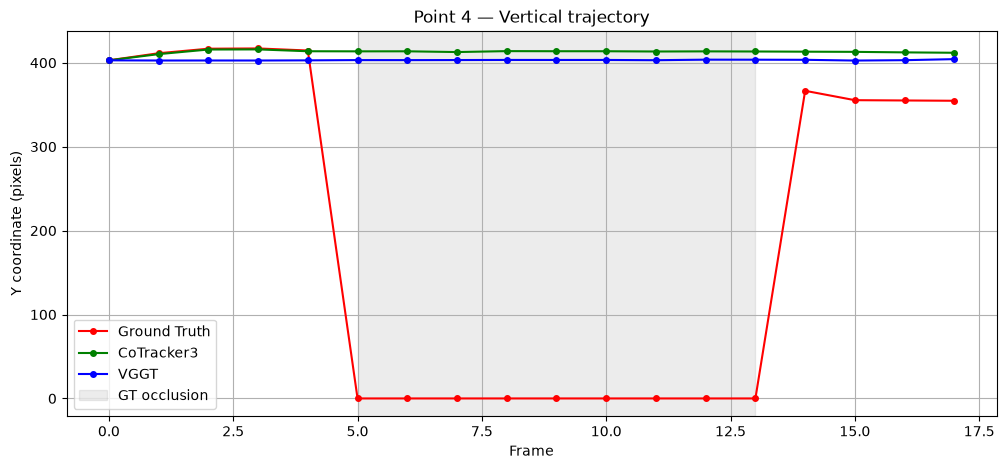

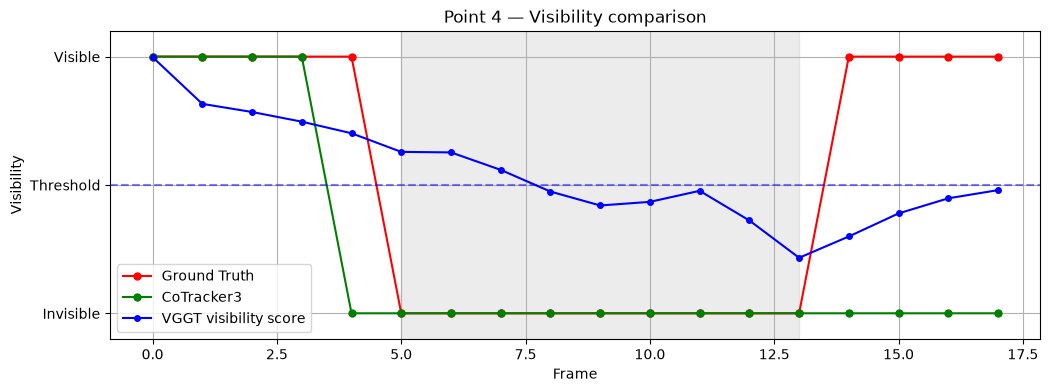

In [10]:

# ============================================================
# 8. COMPARE POINT 4: GROUND TRUTH VS TRACKERS
# ============================================================

point_id = 4

# VGGT only processed the first 18 frames
n_frames = vggt_tracks.shape[0]

frames = np.arange(n_frames)

# Ground-truth visibility
gt_visible = ~gt_occluded[point_id, :n_frames]

# CoTracker3 visibility
cotracker_visible = cotracker_visibility[:n_frames, point_id]

# VGGT visibility scores
vggt_vis_scores = vggt_visibility[:, point_id]

# Convert VGGT visibility scores to Boolean for visualization.
# We use 0.5 provisionally, not as an official benchmark threshold.
vggt_visible = vggt_vis_scores > 0.5


# ============================================================
# PLOT 1: X COORDINATE OVER TIME
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    frames,
    gt_points[point_id, :n_frames, 0],
    "r-o",
    label="Ground Truth",
    markersize=4
)

plt.plot(
    frames,
    cotracker_tracks[:n_frames, point_id, 0],
    "g-o",
    label="CoTracker3",
    markersize=4
)

plt.plot(
    frames,
    vggt_tracks[:, point_id, 0],
    "b-o",
    label="VGGT",
    markersize=4
)

plt.axvspan(5, 13, color="gray", alpha=0.15, label="GT occlusion")

plt.xlabel("Frame")
plt.ylabel("X coordinate (pixels)")
plt.title("Point 4 — Horizontal trajectory")
plt.legend()
plt.grid()
plt.show()


# ============================================================
# PLOT 2: Y COORDINATE OVER TIME
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    frames,
    gt_points[point_id, :n_frames, 1],
    "r-o",
    label="Ground Truth",
    markersize=4
)

plt.plot(
    frames,
    cotracker_tracks[:n_frames, point_id, 1],
    "g-o",
    label="CoTracker3",
    markersize=4
)

plt.plot(
    frames,
    vggt_tracks[:, point_id, 1],
    "b-o",
    label="VGGT",
    markersize=4
)

plt.axvspan(5, 13, color="gray", alpha=0.15, label="GT occlusion")

plt.xlabel("Frame")
plt.ylabel("Y coordinate (pixels)")
plt.title("Point 4 — Vertical trajectory")
plt.legend()
plt.grid()
plt.show()


# ============================================================
# PLOT 3: VISIBILITY
# ============================================================

plt.figure(figsize=(12, 4))

plt.plot(
    frames,
    gt_visible.astype(int),
    "r-o",
    label="Ground Truth",
    markersize=5
)

plt.plot(
    frames,
    cotracker_visible.astype(int),
    "g-o",
    label="CoTracker3",
    markersize=5
)

plt.plot(
    frames,
    vggt_vis_scores,
    "b-o",
    label="VGGT visibility score",
    markersize=4
)

plt.axhline(0.5, color="blue", linestyle="--", alpha=0.5)
plt.axvspan(5, 13, color="gray", alpha=0.15)

plt.xlabel("Frame")
plt.ylabel("Visibility")
plt.title("Point 4 — Visibility comparison")
plt.yticks([0, 0.5, 1], ["Invisible", "Threshold", "Visible"])
plt.ylim(-0.1, 1.1)
plt.legend()
plt.grid()
plt.show()
